In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors = 'coerce').astype(float)

In [5]:
df['TotalCharges'].dtype

dtype('float64')

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [87]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
        'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod',   'Churn']

for col in cat_cols:
    print(df[col].value_counts())
    print()

gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
No                     3473
Yes                    2044
No internet service    15

target is unbalanced, accuracy score might be missleading later on

In [7]:
num_cols =['tenure','MonthlyCharges','TotalCharges']

In [90]:
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.drop('customerID',axis=1,inplace=True)

In [11]:
df[df.duplicated()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
1491,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1739,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes
1932,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
2713,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
2892,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.45,20.45,No
3301,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,Yes
3754,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
4098,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.20,20.20,Yes


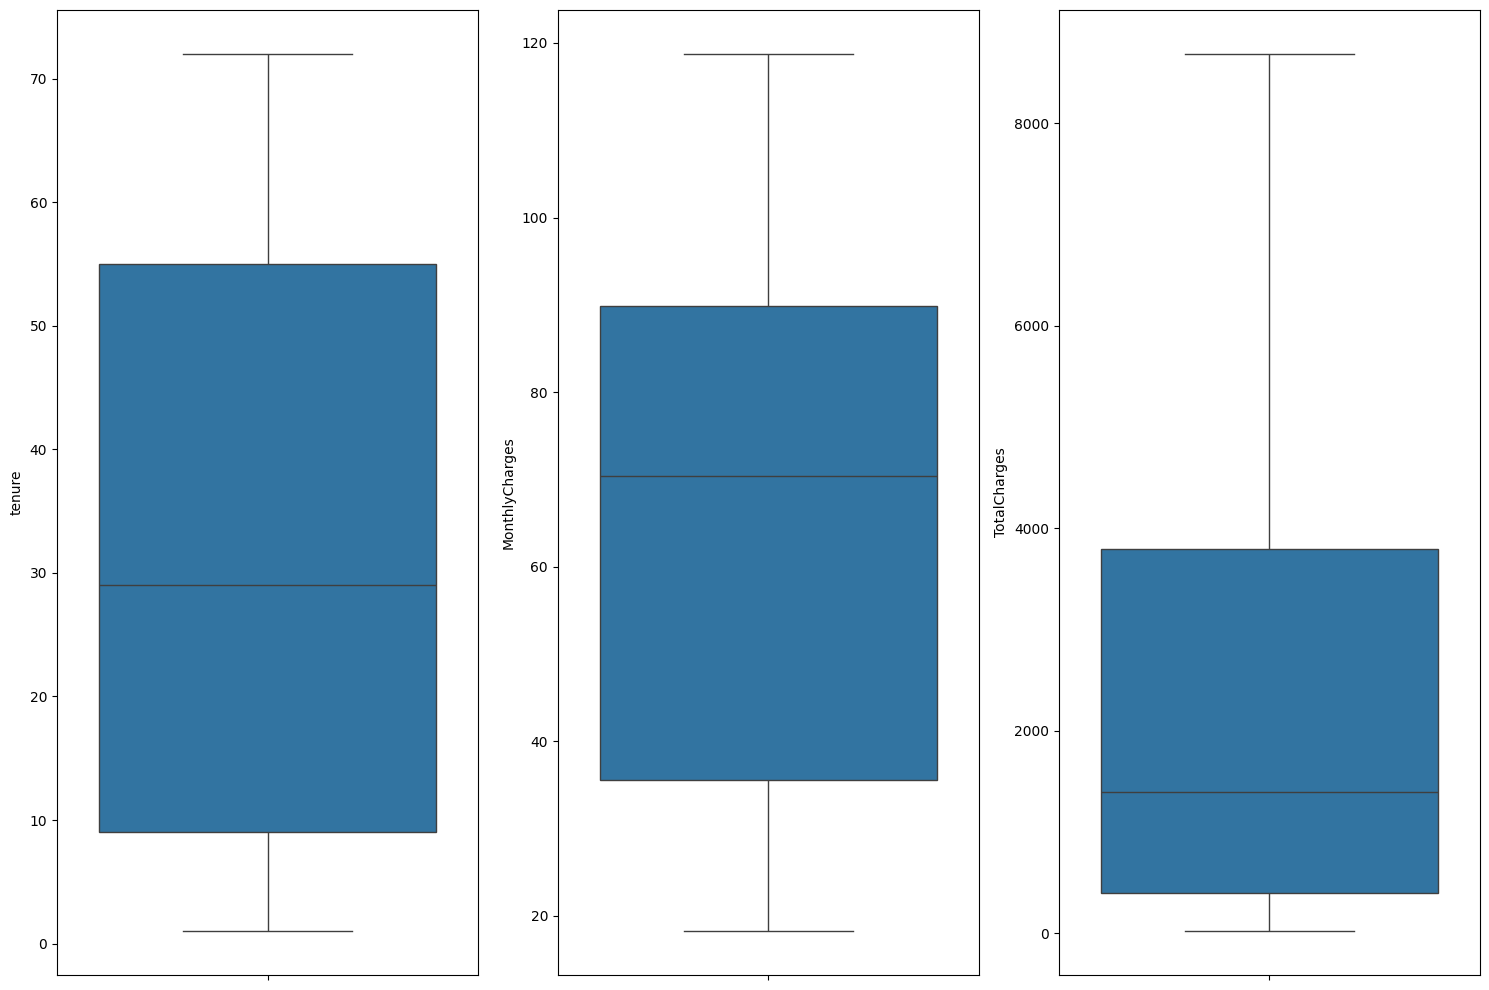

In [95]:
plt.figure(figsize=(15,10))
for i,col in enumerate(num_cols , start=1):
    plt.subplot(1,3,i)
    sns.boxplot(data=df , y=col)

plt.tight_layout()
plt.show()

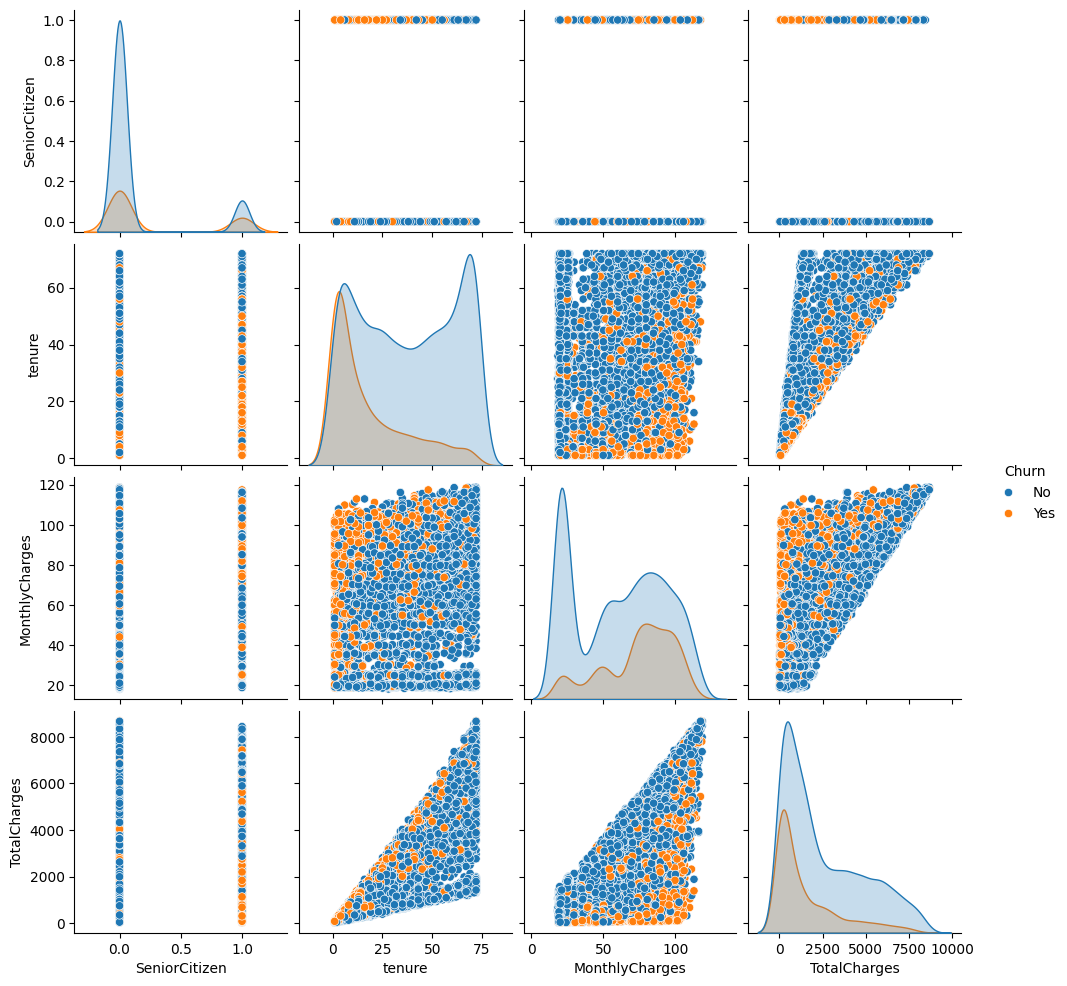

In [96]:
sns.pairplot(df,hue='Churn')
plt.show()

In [97]:
# df[['PhoneService', 'MultipleLines']]



In [98]:
# df.loc[df['PhoneService'] == 'No','PhoneService'] = 'No phone service'

In [99]:
df['PhoneService'].value_counts()

PhoneService
Yes    6352
No      680
Name: count, dtype: int64

In [100]:
# df[['InternetService','OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']]

In [101]:
# df.loc[df['InternetService'] == "No" , 'InternetService'] = 'No internet service'

In [102]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

In [103]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [104]:
"""
['InternetService','OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
'TechSupport', 'StreamingTV', 'StreamingMovies'] => All have 'No internet service'

['PhoneService', 'MultipleLines'] => both have 'No phone service'
"""

"\n['InternetService','OnlineSecurity', 'OnlineBackup', 'DeviceProtection', \n'TechSupport', 'StreamingTV', 'StreamingMovies'] => All have 'No internet service'\n\n['PhoneService', 'MultipleLines'] => both have 'No phone service'\n"

In [59]:
binary_cats = ['gender', 'SeniorCitizen', 'Partner', 'Dependents','PhoneService','PaperlessBilling']
multi_class = ['MultipleLines', 'InternetService', 'OnlineSecurity','OnlineBackup', 'DeviceProtection', 
               'TechSupport', 'StreamingTV','StreamingMovies','PaperlessBilling']
label = 'Churn'

In [60]:
from sklearn.preprocessing import OneHotEncoder ,LabelEncoder , StandardScaler 
from sklearn.model_selection import train_test_split

In [61]:
x = df.drop('Churn',axis=1)
y = df['Churn']

In [62]:
y = y.astype(str)

In [63]:
y.unique()

array(['No', 'Yes'], dtype=object)

In [133]:
x_train,x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y ,shuffle=True)

In [134]:
one_hot = OneHotEncoder(drop='if_binary')
std_scaler = StandardScaler()
label_enc = LabelEncoder()

In [135]:
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
        'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']

In [136]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

### one hot encode and scaling

In [137]:
x_train_enc= one_hot.fit_transform(x_train[cat_cols])
x_test_enc = one_hot.transform(x_test[cat_cols])

In [138]:
x_train_enc = pd.DataFrame(
    x_train_enc.toarray(),
    columns = one_hot.get_feature_names_out(cat_cols),
    index= x_train.index
)

x_test_enc = pd.DataFrame(
    x_test_enc.toarray(),
    columns =one_hot.get_feature_names_out(cat_cols),
    index = x_test.index
)

In [139]:
x_train = pd.concat(
    [x_train.drop(columns=cat_cols) , x_train_enc],
    axis = 1
)

x_test = pd.concat(
    [x_test.drop(columns=cat_cols) , x_test_enc],
    axis = 1
)

In [140]:
x_train.shape

(5625, 40)

In [141]:
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

In [142]:
x_train_scaled[num_cols] = std_scaler.fit_transform(x_train_scaled[num_cols])
x_test_scaled[num_cols] = std_scaler.transform(x_test_scaled[num_cols])

In [143]:
x_train_scaled.shape

(5625, 40)

In [144]:
x_train_scaled.head(1)

,tenure,MonthlyCharges,TotalCharges,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,1.321816,0.981556,1.6599,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [145]:
y_train = label_enc.fit_transform(y_train)
y_test = label_enc.transform(y_test)

In [146]:
y_test

array([0, 0, 0, ..., 0, 0, 0], shape=(1407,))

## Step 2: Baseline Training & Model Comparison

In [147]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import recall_score , precision_score ,f1_score

In [148]:
models_scaled = {
    "Logistic Regression" : LogisticRegression(random_state=42),
    "SVC" : SVC(random_state=42),
    "KNN" : KNeighborsClassifier()
}

models_not_scaled = {
    "Decision Tree" : DecisionTreeClassifier(random_state=42),
    "Random Forest" : RandomForestClassifier(random_state=42),
    "AdaBoost" : AdaBoostClassifier(random_state=42),
    "XGboost" : XGBClassifier(random_state = 42)
}

In [127]:
'''
I care about true positives because these people that I want to make them stay with the company so I want to minimize
the false negatives as much as I can because that means that those customers were leave and i have no idea and i have not 
tried anything to win them back
so I am using both recall and precesion because I care about both FN and TP 
so f1 score is the best choice
accuracy score is not accurate since the target data in imbalanced
'''

'\nI care about true positives because these people that I want to make them stay with the company so I want to minimize\nthe false negatives as much as I can because that means that those customers were leave and i have no idea and i have not \ntried anything to win them back\nso I am using both recall and precesion because I care about both FN and TP \nso f1 score is the best choice\naccuracy score is not accurate since the target data in imbalanced\n'

In [128]:
'''
data size is small-mid
no outliers so not noisy
many features
binary clsf
imbalanced target
overlapped

models that might work => DT would work the best
                          KNN but might struggle with num of feats
                          SVC rbf might struggle with num of feats
                          
'''

'\ndata size is small-mid\nno outliers so not noisy\nmany features\nbinary clsf\nimbalanced target\noverlapped\n\nmodels that might work => DT would work the best\n                          KNN but might struggle with num of feats\n                          SVC rbf might struggle with num of feats\n                          \n'

In [155]:
trained_models = {}
models_vs_score = {
    "Model" : [] ,
    "F1" : [] ,
    "Recall" : [],
    "Precision" : []
}

In [156]:
for model_name , model in models_scaled.items():
    model = model.fit(x_train_scaled,y_train)
    y_pred = model.predict(x_test_scaled)

    f1 = f1_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test , y_pred)

    trained_models[model_name] = model
    models_vs_score["Model"].append(model_name)
    models_vs_score["F1"].append(f1)
    models_vs_score["Precision"].append(precision)
    models_vs_score["Recall"].append(recall)

    print(f"{model_name}:")
    print(f"F1: {f1}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print("\n")
    

Logistic Regression:
F1: 0.6099290780141844
Precision: 0.649546827794562
Recall: 0.5748663101604278


SVC:
F1: 0.5568862275449101
Precision: 0.6326530612244898
Recall: 0.49732620320855614


KNN:
F1: 0.5486018641810919
Precision: 0.5464190981432361
Recall: 0.5508021390374331




In [157]:
for model_name , model in models_not_scaled.items():
    model = model.fit(x_train,y_train)
    y_pred = model.predict(x_test)

    f1 = f1_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test , y_pred)

    trained_models[model_name] = model
    models_vs_score["Model"].append(model_name)
    models_vs_score["F1"].append(f1)
    models_vs_score["Precision"].append(precision)
    models_vs_score["Recall"].append(recall)

    print(f"{model_name}:")
    print(f"F1: {f1}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print("\n")
    

Decision Tree:
F1: 0.4926372155287818
Precision: 0.4932975871313673
Recall: 0.4919786096256685


Random Forest:
F1: 0.5560538116591929
Precision: 0.6305084745762712
Recall: 0.49732620320855614


AdaBoost:
F1: 0.5705967976710334
Precision: 0.6261980830670927
Recall: 0.5240641711229946


XGboost:
F1: 0.5469613259668509
Precision: 0.5657142857142857
Recall: 0.5294117647058824




In [158]:
models_vs_score = pd.DataFrame(models_vs_score)
models_vs_score

,Model,F1,Recall,Precision
0,Logistic Regression,0.609929,0.574866,0.649547
1,SVC,0.556886,0.497326,0.632653
2,KNN,0.548602,0.550802,0.546419
3,Decision Tree,0.492637,0.491979,0.493298
4,Random Forest,0.556054,0.497326,0.630508
5,AdaBoost,0.570597,0.524064,0.626198
6,XGboost,0.546961,0.529412,0.565714


In [133]:
'''
LR:
    it has the highest Percesion so out of all the predicted trues 64% was actual true
    recall even though it missed 42% of the actual trues but we can try and tune it 
    f1 is the most balanced as well
    beside tuning we will try to minimize the num of feats
'''

'\nLR:\n    it has the highest Percesion so out of all the predicted trues 64% was actual true\n    recall even though it missed 42% of the actual trues but we can try and tune it \n    f1 is the most balanced as well\n    beside tuning we will try to minimize the num of feats\n'

### Logistic REgression

In [159]:
from sklearn.model_selection import GridSearchCV

In [35]:
lr_model = LogisticRegression(random_state=42)

In [136]:
params = [{
    "C" : [0.001,0.01,0.1,1,10],
    'class_weight' : [None , 'balanced'],
    'solver' : ['liblinear'],
    'penalty' : ['l1','l2'],
    'max_iter' : [100,500,1000,2000]
},
{
    "C" : [0.001,0.01,0.1,1],
    'class_weight' : [None , 'balanced'],
    'solver' : ['lbfgs'],
    'penalty' : ['l2'],
    'max_iter' : [100,500,1000,2000]
}
]

In [137]:
grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=params,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

In [138]:
grid_search.fit(x_train_scaled,y_train)

Fitting 5 folds for each of 112 candidates, totalling 560 fits


GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid=[{'C': [0.001, 0.01, 0.1, 1, 10],
                          'class_weight': [None, 'balanced'],
                          'max_iter': [100, 500, 1000, 2000],
                          'penalty': ['l1', 'l2'], 'solver': ['liblinear']},
                         {'C': [0.001, 0.01, 0.1, 1],
                          'class_weight': [None, 'balanced'],
                          'max_iter': [100, 500, 1000, 2000], 'penalty': ['l2'],
                          'solver': ['lbfgs']}],
             scoring='f1', verbose=2)

In [139]:
grid_search.best_estimator_

LogisticRegression(C=1, class_weight='balanced', random_state=42,
                   solver='liblinear')

In [140]:
grid_search.best_params_

{'C': 1,
 'class_weight': 'balanced',
 'max_iter': 100,
 'penalty': 'l2',
 'solver': 'liblinear'}

In [141]:
grid_search.best_score_

np.float64(0.6333294566224069)

In [160]:
best_LR = LogisticRegression(
    C = 1,
 class_weight= 'balanced',
 max_iter= 100,
 penalty= 'l2',
 solver= 'liblinear',
 random_state=42
)

In [161]:
best_LR.fit(x_train_scaled,y_train)

LogisticRegression(C=1, class_weight='balanced', random_state=42,
                   solver='liblinear')

In [162]:
y_pred = best_LR.predict(x_test_scaled)

In [163]:
f1 = f1_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test , y_pred)

print(f"F1: {f1}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

F1: 0.6055045871559633
Precision: 0.48929159802306427
Recall: 0.7941176470588235


In [40]:
best_LR.score(x_train_scaled,y_train)

0.7555555555555555

In [41]:
best_LR.score(x_test_scaled,y_test)

0.7249466950959488

In [148]:
'''
after tuning Logistic regression it got better but stil not the best, so may be I will try use the threshold 
because of the imbalancind
''' 

'\nafter tuning Logistic regression it got better but stil not the best, so may be I will try use the threshold \nbecause of the imbalancind\n'

In [42]:
y_proba = best_LR.predict_proba(x_test_scaled)[:,1]
y_proba

array([0.05034005, 0.78536272, 0.01425589, ..., 0.27324492, 0.06595875,
       0.01371925], shape=(1407,))

In [43]:
thresholds = [0.2,0.3,0.4,0.5 ,0.6,0.7]

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    f1 = f1_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)
    recall = recall_score(y_test , y_pred)

    print(f"threshold: {threshold}")
    print(f"F1: {f1}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print("\n")



threshold: 0.2
F1: 0.5510360706062931
Precision: 0.38643702906350913
Recall: 0.9598930481283422


threshold: 0.3
F1: 0.5726072607260726
Precision: 0.41408114558472553
Recall: 0.9278074866310161


threshold: 0.4
F1: 0.5954337899543379
Precision: 0.4521497919556172
Recall: 0.8716577540106952


threshold: 0.5
F1: 0.6055045871559633
Precision: 0.48929159802306427
Recall: 0.7941176470588235


threshold: 0.6
F1: 0.6182237600922722
Precision: 0.5436105476673428
Recall: 0.7165775401069518


threshold: 0.7
F1: 0.6143617021276596
Precision: 0.6111111111111112
Recall: 0.6176470588235294




In [151]:
"""
if i cared about just catching as many churns as I can the using small threshold might work but the percision would be low 
since it also mistaked not churns with churns, there will be alot of FP
"""

'\nif i cared about just catching as many churns as I can the using small threshold might work but the percision would be low \nsince it also mistaked not churns with churns, there will be alot of FP\n'

In [152]:
models_vs_score

,Model,F1,Recall,Precision
0,Logistic Regression,0.609929,0.574866,0.649547
1,SVC,0.556886,0.497326,0.632653
2,KNN,0.548602,0.550802,0.546419
3,Decision Tree,0.492637,0.491979,0.493298
4,Random Forest,0.556054,0.497326,0.630508
5,AdaBoost,0.570597,0.524064,0.626198
6,XGboost,0.546961,0.529412,0.565714


In [153]:
"""
even though the scores of the base model do not really show that DT would perform good but knowing How each model works 
DT might work the best, so I will try it
"""

'\neven though the scores of the base model do not really show that DT would perform good but knowing How each model works \nDT might work the best, so I will try it\n'

---------------------------------

### Decision Tree

In [154]:
trained_models['Decision Tree'].get_depth()

23

In [155]:
trained_models['Decision Tree'].get_n_leaves()

np.int64(1115)

In [156]:
trained_models['Decision Tree'].score(x_train,y_train)

0.9987555555555555

In [157]:
trained_models['Decision Tree'].score(x_test,y_test)

0.7306325515280739

In [158]:
"overfitting"

'overfitting'

In [159]:
dt = DecisionTreeClassifier(random_state=42)

In [160]:
params={
    'criterion' : ["gini" , 'entropy'] , 
    'max_depth' : [5,6,8,10,15] , 
    'min_samples_split' : [2,5,10,20],
    'class_weight': [None,"balanced"],
    'max_leaf_nodes'  : [20,30,40,50 , 100 , 150 , 200 , 500, None],
    'min_samples_leaf' : [2,5,10,15,20]
}

In [161]:
grid_search_dt = GridSearchCV(
    estimator=dt ,
    param_grid=params,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

In [162]:
grid_search_dt.fit(x_train,y_train)

Fitting 5 folds for each of 3600 candidates, totalling 18000 fits


KeyboardInterrupt: 

In [ ]:
grid_search_dt.best_score_

np.float64(0.6225657590135232)

In [ ]:
grid_search_dt.best_params_

{'class_weight': 'balanced',
 'criterion': 'entropy',
 'max_depth': 8,
 'max_leaf_nodes': 30,
 'min_samples_leaf': 10,
 'min_samples_split': 2}

In [164]:
best_dt = DecisionTreeClassifier(
    class_weight= 'balanced',
 criterion= 'entropy',
 max_depth= 8,
 max_leaf_nodes= 30,
 min_samples_split= 2,
 min_samples_leaf = 10 ,
 random_state= 42
)

In [165]:
best_dt.fit(x_train,y_train)

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=8, max_leaf_nodes=30, min_samples_leaf=10,
                       random_state=42)

In [46]:
y_pred = best_dt.predict(x_test)

In [47]:
f1 = f1_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test , y_pred)
print(f"F1: {f1}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

F1: 0.6162402669632926
Precision: 0.5276190476190477
Recall: 0.7406417112299465


------------------

In [ ]:
'''
lets try random forest and knn
'''

'\nlets try random forest and knn\n'

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [ ]:
rf_model.score(x_train,y_train)

0.9987555555555555

In [ ]:
rf_model.score(x_test,y_test)

0.7889125799573561

In [ ]:
y_pred = rf_model.predict(x_test)
f1_score(y_test,y_pred)

0.5560538116591929

In [ ]:
'''there is generalaization issue'''

'there is generalaization issue'

In [ ]:
knn= KNeighborsClassifier()

In [ ]:
knn_params =[
    {
    "n_neighbors":[10,11,12,13,14], 
    "weights":['uniform','distance'],
    "algorithm":["auto",  'brute'],  
    'p':[1,2,4,6,8], 
    'metric':['minkowski'], 
   
    }
    ,
    {
    "n_neighbors":[10,11,12,13,14], 
    "weights":['uniform','distance'],
    "algorithm":["auto",  'brute'],  
    'metric' : ['euclidean', 'manhattan']
    }
]

In [166]:
from sklearn.model_selection import GridSearchCV

In [ ]:
knn_gridSearch = GridSearchCV(
    estimator=knn,
    param_grid=knn_params,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

In [ ]:
knn_gridSearch.fit(x_train_scaled,y_train)

Fitting 5 folds for each of 140 candidates, totalling 700 fits


GridSearchCV(cv=5, estimator=KNeighborsClassifier(), n_jobs=-1,
             param_grid=[{'algorithm': ['auto', 'brute'],
                          'metric': ['minkowski'],
                          'n_neighbors': [10, 11, 12, 13, 14],
                          'p': [1, 2, 4, 6, 8],
                          'weights': ['uniform', 'distance']},
                         {'algorithm': ['auto', 'brute'],
                          'metric': ['euclidean', 'manhattan'],
                          'n_neighbors': [10, 11, 12, 13, 14],
                          'weights': ['uniform', 'distance']}],
             scoring='f1', verbose=2)

In [ ]:
y_pred = knn_gridSearch.predict(x_test_scaled)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.5405405405405406
REcall:  0.5347593582887701
Percision:  0.546448087431694


In [ ]:
knn_gridSearch.best_estimator_

KNeighborsClassifier(n_neighbors=13, p=1)

-------------------

In [50]:
params_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

grid_rf = GridSearchCV(
    estimator=trained_models['Random Forest'],
    param_grid=params_rf,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_rf.fit(x_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'class_weight': [None, 'balanced'],
                         'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 5],
                         'min_samples_split': [2, 10],
                         'n_estimators': [100, 200]},
             scoring='f1', verbose=2)

In [51]:
grid_rf.best_estimator_

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=5, n_estimators=200, random_state=42)

In [52]:
grid_rf.best_params_

{'class_weight': 'balanced',
 'max_depth': 10,
 'max_features': 'sqrt',
 'min_samples_leaf': 5,
 'min_samples_split': 2,
 'n_estimators': 200}

In [167]:
best_rf = RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=5, n_estimators=200, random_state=42)
best_rf.fit(x_train,y_train)


RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=5, n_estimators=200, random_state=42)

In [54]:
y_pred = best_rf.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6292629262926293
REcall:  0.7647058823529411
Percision:  0.5345794392523364


--------------------------------------------

In [ ]:
trained_models

{'Logistic Regression': LogisticRegression(random_state=42),
 'SVC': SVC(random_state=42),
 'KNN': KNeighborsClassifier(),
 'Decision Tree': DecisionTreeClassifier(random_state=42),
 'Random Forest': RandomForestClassifier(random_state=42),
 'AdaBoost': AdaBoostClassifier(random_state=42),
 'XGboost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=None, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_

In [ ]:
svc_params = [
    {
        'kernel': ['linear'],
        'C': [0.01, 0.1, 1, 10]
    },
    {
        'kernel': ['rbf'],
        'C': [0.1, 1, 10],
        'gamma': ['scale', 0.01, 0.1]
    }
]

In [ ]:
svc_grid = GridSearchCV(
    estimator=trained_models["SVC"],
    param_grid=svc_params ,
    cv=5,
    n_jobs= -1,
    verbose= 2,
    scoring="f1"
)

svc_grid.fit(x_train_scaled,y_train)

Fitting 5 folds for each of 13 candidates, totalling 65 fits


GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid=[{'C': [0.01, 0.1, 1, 10], 'kernel': ['linear']},
                         {'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1],
                          'kernel': ['rbf']}],
             scoring='f1', verbose=2)

In [ ]:
svc_grid.best_estimator_

SVC(C=10, kernel='linear', random_state=42)

In [ ]:
svc_grid.best_params_

{'C': 10, 'kernel': 'linear'}

In [ ]:
svc_grid.best_score_

np.float64(0.5835985775349048)

In [168]:
best_svc = SVC(random_state=42 , C= 10, kernel='linear')
best_svc.fit(x_train_scaled,y_train)

SVC(C=10, kernel='linear', random_state=42)

In [56]:
y_pred = best_svc.predict(x_test_scaled)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.5911047345767575
REcall:  0.5508021390374331
Percision:  0.6377708978328174


------------------------------------------------------------------------------

In [ ]:
ada_model = AdaBoostClassifier(
    estimator=best_dt,
    random_state=42
)
ada_model.fit(x_train,y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                    criterion='entropy',
                                                    max_depth=8,
                                                    max_leaf_nodes=30,
                                                    min_samples_leaf=10,
                                                    random_state=42),
                   random_state=42)

In [ ]:
y_pred = ada_model.predict(x_test_scaled)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.5606694560669456
REcall:  0.7165775401069518
Percision:  0.46048109965635736


In [ ]:
ada_params = [
    {
        'estimator' : [
            DecisionTreeClassifier(max_depth=1,random_state=42),
            DecisionTreeClassifier(max_depth=2,random_state=42)
        ],
        'n_estimators' : [50,100,150,200],
        'learning_rate' : [0.01,0.1,1.0]
    },
    {
        'estimator' : [best_dt] ,
        'n_estimators' : [25,50,100] ,
        'learning_rate' : [0.01,0.1]
    }
]

In [ ]:
ada_grid = GridSearchCV(
    estimator= trained_models['AdaBoost'],
    param_grid=ada_params,
    cv=5,
    scoring = 'f1' ,
    verbose=2,
    n_jobs=-1

)

ada_grid.fit(x_train , y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=42), n_jobs=-1,
             param_grid=[{'estimator': [DecisionTreeClassifier(max_depth=1,
                                                               random_state=42),
                                        DecisionTreeClassifier(max_depth=2,
                                                               random_state=42)],
                          'learning_rate': [0.01, 0.1, 1.0],
                          'n_estimators': [50, 100, 150, 200]},
                         {'estimator': [DecisionTreeClassifier(class_weight='balanced',
                                                               criterion='entropy',
                                                               max_depth=8,
                                                               max_leaf_nodes=30,
                                                               min_samples_leaf=10,
                                                               random_state=42)],
                          'learning_rate': [0.01, 0.1],
                          'n_estimators': [25, 50, 100]}],
             scoring='f1', verbose=2)

In [ ]:
ada_grid.best_score_

np.float64(0.6347207622969241)

In [ ]:
ada_grid.best_params_

{'estimator': DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                        max_depth=8, max_leaf_nodes=30, min_samples_leaf=10,
                        random_state=42),
 'learning_rate': 0.1,
 'n_estimators': 25}

In [169]:
best_ada = AdaBoostClassifier(estimator=best_dt , learning_rate= 0.1 , n_estimators=25, random_state=42)
best_ada.fit(x_train ,y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                    criterion='entropy',
                                                    max_depth=8,
                                                    max_leaf_nodes=30,
                                                    min_samples_leaf=10,
                                                    random_state=42),
                   learning_rate=0.1, n_estimators=25, random_state=42)

In [58]:
y_pred = best_ada.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6247379454926625
REcall:  0.7967914438502673
Percision:  0.5137931034482759


--------------------

In [170]:
xgb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4, 5],
    'min_child_weight': [1, 3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'objective':['binary:logistic'],
    'eval_metric':['logloss'],
}

In [173]:
xgb_grid = GridSearchCV(
    estimator=trained_models['XGboost'],
    param_grid=xgb_params,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=2
)

In [174]:
xgb_grid.fit(x_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=Non...
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'eval_metric': ['logloss'],
                         'learning_rate': [0.05, 0.1], 'max_depth': [3, 4, 5],
                         'min_child_weight': [1, 3], 'n_estimators': [100, 200],
                         'objective': ['binary:logistic'],
                         'subsample': [0.8, 1.0]},
             scoring='f1', verbose=2)

In [175]:
xgb_grid.best_params_

{'colsample_bytree': 1.0,
 'eval_metric': 'logloss',
 'learning_rate': 0.1,
 'max_depth': 4,
 'min_child_weight': 1,
 'n_estimators': 100,
 'objective': 'binary:logistic',
 'subsample': 1.0}

In [177]:
xgb_grid.best_estimator_

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [176]:
xgb_grid.best_score_

np.float64(0.5921428338803324)

In [180]:
best_xgb = XGBClassifier(colsample_bytree = 1.0,
 eval_metric= 'logloss',
 learning_rate= 0.1,
 max_depth= 4,
 min_child_weight= 1,
 n_estimators= 100,
 objective= 'binary:logistic',
 subsample= 1.0 , random_state = 42)

In [181]:
best_xgb.fit(x_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=1, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [182]:
y_pred = best_ada.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6247379454926625
REcall:  0.7967914438502673
Percision:  0.5137931034482759


model |	F1 | recall | percision

LR | 60 | 79 | 48

DT | 61	| 74 | 52

RF | 63	| 76 | 53

KNN | 54 | 53 | 54

SVC | 59 | 55 | 63

AdaBoost |	62	| 79 | 51

XGboost	| 62 | 79 | 51


## Voting rf, ada , xgb

In [183]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('ada', best_ada),
        ('xgb', best_xgb)
    ],
    voting='soft',
    weights=[1, 1, 1],
    n_jobs=-1
)

In [ ]:
voting_model.fit(x_train, y_train)

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(class_weight='balanced',
                                                     max_depth=10,
                                                     min_samples_leaf=5,
                                                     n_estimators=200,
                                                     random_state=42)),
                             ('ada',
                              AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                                  criterion='entropy',
                                                                                  max_depth=8,
                                                                                  max_leaf_nodes=30,
                                                                                  min_samples_leaf=10,
                                                                                  random_state=42),
                                                 learning_rate=0.1,
                                                 n_estimators=...
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=4,
                                            max_leaves=None, min_child_weight=1,
                                            missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 n_jobs=-1, voting='soft', weights=[1, 1, 1])

In [185]:
y_pred = voting_model.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6280417149478563
REcall:  0.7245989304812834
Percision:  0.5541922290388548


In [186]:
'''
since my goal is to get as many tues as possible so i will judge based on the recall score
'''

'\nsince my goal is to get as many tues as possible so i will judge based on the recall score\n'

In [187]:
voting_model2 = VotingClassifier(
    estimators=[
        ('lr', best_LR),
        ('ada', best_ada),
        ('xgb', best_xgb)
    ],
    voting='soft',
    weights=[1, 1, 1],
    n_jobs=-1
)

In [188]:
voting_model2.fit(x_train, y_train)

VotingClassifier(estimators=[('lr',
                              LogisticRegression(C=1, class_weight='balanced',
                                                 random_state=42,
                                                 solver='liblinear')),
                             ('ada',
                              AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                                  criterion='entropy',
                                                                                  max_depth=8,
                                                                                  max_leaf_nodes=30,
                                                                                  min_samples_leaf=10,
                                                                                  random_state=42),
                                                 learning_rate=0.1,
                                                 n_estimators=25,
                                                 random_state=42)),
                             ('xgb',
                              XG...
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=4,
                                            max_leaves=None, min_child_weight=1,
                                            missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 n_jobs=-1, voting='soft', weights=[1, 1, 1])

In [189]:
y_pred = voting_model2.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6288308740068105
REcall:  0.7406417112299465
Percision:  0.5463510848126233


In [190]:
'''
with voting it is not any better so i will pick the best percision beside f1 
'''

'\nwith voting it is not any better so i will pick the best percision beside f1 \n'

In [191]:
voting_model3 = VotingClassifier(
    estimators=[
        ('ada', best_ada),
        ('xgb', best_xgb)
    ],
    voting='soft',
    weights=[1, 1],
    n_jobs=-1
)

In [192]:
voting_model3.fit(x_train, y_train)

VotingClassifier(estimators=[('ada',
                              AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                                  criterion='entropy',
                                                                                  max_depth=8,
                                                                                  max_leaf_nodes=30,
                                                                                  min_samples_leaf=10,
                                                                                  random_state=42),
                                                 learning_rate=0.1,
                                                 n_estimators=25,
                                                 random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_b...
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=0.1, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=4,
                                            max_leaves=None, min_child_weight=1,
                                            missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 n_jobs=-1, voting='soft', weights=[1, 1])

In [193]:
y_pred = voting_model3.predict(x_test)
print("F1: ", f1_score(y_test,y_pred))
print("REcall: ",recall_score(y_test,y_pred))
print("Percision: ",precision_score(y_test,y_pred))

F1:  0.6220095693779905
REcall:  0.6951871657754011
Percision:  0.5627705627705628


In [194]:
best_xgb.score(x_train,y_train)

0.8368

In [196]:
best_xgb.score(x_test,y_test)

0.7924662402274343

In [197]:
best_ada.score(x_train,y_train)

0.7729777777777778

In [198]:
best_ada.score(x_test,y_test)

0.7455579246624022

In [199]:
'''
XGB is the best model , best recall and best balanced score
'''

'\nXGB is the best model , best recall and best balanced score\n'

# Step 4: Save the Model

In [200]:
import joblib

In [201]:
bundle = {
    'encoder' : one_hot,
    'model' : best_xgb
}

In [202]:
joblib.dump(bundle,'churn_model.pkl')

['churn_model.pkl']

# Needed data for the deloyment

In [203]:
cat_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [213]:
len(cat_cols)/2

8.0

In [204]:
x_train.columns

Index(['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male',
       'SeniorCitizen_1', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'InternetService_DSL',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No', 'OnlineSecurity_No internet service',
       'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No', 'DeviceProtection_No internet service',
       'DeviceProtection_Yes', 'TechSupport_No',
       'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Bank transfer (automatic)',

In [210]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [211]:
len(num_cols)

3

In [209]:
len(x.columns)

19

In [ ]:
x.columns

<bound method Index.__len__ of Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')>

In [206]:
'Churn'

'Churn'

In [207]:
'''
data => data frame for the inputs

cat_data = encoder.transform(data[cat_cols])

input = pd.DataFrame(
    cat_data.toarray(),
    columns = encoder.get_feature_names_out(cat_cols),
    index= data.index
)


input = pd.concat(
    [data.drop(columns=cat_cols) , input],
    axis = 1
)
'''

'\ndata => data frame for the inputs\n\ncat_data = encoder.transform(data[cat_cols])\n\ninput = pd.DataFrame(\n    cat_data.toarray(),\n    columns = encoder.get_feature_names_out(cat_cols),\n    index= data.index\n)\n\n\ninput = pd.concat(\n    [data.drop(columns=cat_cols) , input],\n    axis = 1\n)\n'

In [ ]:
'''
gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Churn
No     5174
Yes    1869
Name: count, dtype: int64

'''

In [214]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [215]:
df.head(1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
